# Logistic regression: will a Chicago traffic crash result in an injury?

Target: INJURIES_TOTAL > 0

Rebuilt from the group's logistic regression script. The modelling and evaluation code is
unchanged. Additions are marked "(ADDED)": test-set fingerprint, saved prediction/summary files,
and shift tests at the end (the original script had none).

In [1]:
%matplotlib inline
import os
import time
import pickle
import hashlib
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.isotonic import IsotonicRegression
from sklearn.inspection import permutation_importance
from sklearn.calibration import calibration_curve
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score, balanced_accuracy_score,
    matthews_corrcoef, roc_auc_score, average_precision_score, log_loss, brier_score_loss,
    confusion_matrix, roc_curve, precision_recall_curve,
)

warnings.filterwarnings("ignore")

## CONFIG

`DATA_PATH` must be the same CSV the random forest notebook used, and `SPLIT_MODE` must match. Everything in sections 1-15 is the group's original logistic regression code; sections 16-17 and the fingerprint line are additions.

In [2]:
DATA_PATH = "crashes.csv"   # <- must be the SAME file used in the random forest notebook
SPLIT_MODE = "random"      # "random" or "temporal" (train on earliest, test on latest)
USE_CONTRIBUTORY_CAUSE = False  # PRIM/SEC causes are assigned post-investigation; keep False
USE_CLASS_WEIGHT = False   # False keeps probabilities calibrated; True boosts recall
C_GRID = [0.01, 0.1, 1, 10]
N_BOOT = 200
SEED = 42
# ============================================================================

## 1. LOAD

In [3]:
df = pd.read_csv(DATA_PATH, low_memory=False)
df.columns = [c.strip().upper() for c in df.columns]
print(f"Loaded {df.shape[0]:,} rows, {df.shape[1]} columns")

df = df[df["INJURIES_TOTAL"].notna()].copy()
df["y"] = (df["INJURIES_TOTAL"] > 0).astype(int)
print(f"Injury rate: {df['y'].mean():.3%}  (n={len(df):,})")

df["CRASH_DATE"] = pd.to_datetime(df["CRASH_DATE"], errors="coerce")
df = df[df["CRASH_DATE"].notna()].copy()

Loaded 405,144 rows, 49 columns
Injury rate: 16.596%  (n=404,199)


## 2. FEATURES

In [4]:
# Leakage excluded on purpose: INJURIES_*, MOST_SEVERE_INJURY, CRASH_TYPE (defines the
# label), DAMAGE, DATE_POLICE_NOTIFIED, REPORT_TYPE (all post-crash), plus ID/address cols.
df["HOUR_SIN"] = np.sin(2 * np.pi * df["CRASH_HOUR"] / 24)
df["HOUR_COS"] = np.cos(2 * np.pi * df["CRASH_HOUR"] / 24)
df["IS_WEEKEND"] = df["CRASH_DAY_OF_WEEK"].isin([1, 7]).astype(int)  # 1=Sun, 7=Sat

NUM_COLS = ["POSTED_SPEED_LIMIT", "LANE_CNT", "NUM_UNITS", "CRASH_HOUR",
            "HOUR_SIN", "HOUR_COS", "IS_WEEKEND", "CRASH_MONTH"]
CAT_COLS = ["TRAFFIC_CONTROL_DEVICE", "DEVICE_CONDITION", "WEATHER_CONDITION",
            "LIGHTING_CONDITION", "FIRST_CRASH_TYPE", "TRAFFICWAY_TYPE", "ALIGNMENT",
            "ROADWAY_SURFACE_COND", "ROAD_DEFECT", "INTERSECTION_RELATED_I",
            "NOT_RIGHT_OF_WAY_I", "HIT_AND_RUN_I", "CRASH_DAY_OF_WEEK"]
if USE_CONTRIBUTORY_CAUSE:
    CAT_COLS += ["PRIM_CONTRIBUTORY_CAUSE", "SEC_CONTRIBUTORY_CAUSE"]

NUM_COLS = [c for c in NUM_COLS if c in df.columns]
CAT_COLS = [c for c in CAT_COLS if c in df.columns]
FEATURES = NUM_COLS + CAT_COLS

for c in NUM_COLS:
    df[c] = pd.to_numeric(df[c], errors="coerce")
for c in CAT_COLS:
    df[c] = df[c].astype(str).replace({"nan": "MISSING", "": "MISSING"}).fillna("MISSING")

## 3. SPLIT

The fingerprint printed here must equal the random forest notebook's (`ab504b8b` in the group's run).

In [5]:
if SPLIT_MODE == "temporal":
    df = df.sort_values("CRASH_DATE").reset_index(drop=True)
    n = len(df)
    tr, va, te = df.iloc[:int(.6 * n)], df.iloc[int(.6 * n):int(.8 * n)], df.iloc[int(.8 * n):]
else:
    tr, tmp = train_test_split(df, test_size=0.4, stratify=df["y"], random_state=SEED)
    va, te = train_test_split(tmp, test_size=0.5, stratify=tmp["y"], random_state=SEED)

X_tr, y_tr = tr[FEATURES], tr["y"].values
X_va, y_va = va[FEATURES], va["y"].values
X_te, y_te = te[FEATURES], te["y"].values
print(f"Split ({SPLIT_MODE}): train={len(tr):,} val={len(va):,} test={len(te):,}")

# (ADDED) must equal the random forest run's fingerprint
print("Test-set fingerprint:", hashlib.md5(np.asarray(te.index).tobytes()).hexdigest()[:8])
print("Features used:", FEATURES)

Split (random): train=242,519 val=80,840 test=80,840
Test-set fingerprint: ab504b8b
Features used: ['POSTED_SPEED_LIMIT', 'LANE_CNT', 'NUM_UNITS', 'CRASH_HOUR', 'HOUR_SIN', 'HOUR_COS', 'IS_WEEKEND', 'CRASH_MONTH', 'TRAFFIC_CONTROL_DEVICE', 'DEVICE_CONDITION', 'WEATHER_CONDITION', 'LIGHTING_CONDITION', 'FIRST_CRASH_TYPE', 'TRAFFICWAY_TYPE', 'ALIGNMENT', 'ROADWAY_SURFACE_COND', 'ROAD_DEFECT', 'INTERSECTION_RELATED_I', 'NOT_RIGHT_OF_WAY_I', 'HIT_AND_RUN_I', 'CRASH_DAY_OF_WEEK']


## 4. HELPERS

In [6]:
def build_pipe(C, num_cols, cat_cols):
    pre = ColumnTransformer([
        ("num", Pipeline([("imp", SimpleImputer(strategy="median")),
                          ("sc", StandardScaler())]), num_cols),
        ("cat", OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=50), cat_cols),
    ])
    clf = LogisticRegression(C=C, max_iter=2000, solver="lbfgs",
                             class_weight="balanced" if USE_CLASS_WEIGHT else None)
    return Pipeline([("pre", pre), ("clf", clf)])


def ece_score(y, p, n_bins=10):
    bins = np.linspace(0, 1, n_bins + 1)
    idx = np.clip(np.digitize(p, bins) - 1, 0, n_bins - 1)
    ece = 0.0
    for b in range(n_bins):
        m = idx == b
        if m.any():
            ece += m.mean() * abs(y[m].mean() - p[m].mean())
    return ece


def metrics(y, p, thr=0.5):
    p = np.clip(p, 1e-7, 1 - 1e-7)
    yhat = (p >= thr).astype(int)
    return {
        "accuracy": accuracy_score(y, yhat),
        "precision": precision_score(y, yhat, zero_division=0),
        "recall": recall_score(y, yhat, zero_division=0),
        "f1": f1_score(y, yhat, zero_division=0),
        "balanced_acc": balanced_accuracy_score(y, yhat),
        "mcc": matthews_corrcoef(y, yhat),
        "roc_auc": roc_auc_score(y, p),
        "pr_auc": average_precision_score(y, p),
        "log_loss": log_loss(y, p),
        "brier": brier_score_loss(y, p),
        "ece": ece_score(y, p),
    }


def best_f1_threshold(y, p):
    prec, rec, thr = precision_recall_curve(y, p)
    f1 = 2 * prec[:-1] * rec[:-1] / np.clip(prec[:-1] + rec[:-1], 1e-12, None)
    return thr[np.argmax(f1)]


def recall_target_threshold(y, p, target=0.90):
    """Highest threshold that still achieves >= target recall."""
    _, rec, thr = precision_recall_curve(y, p)
    ok = np.where(rec[:-1] >= target)[0]
    return thr[ok[-1]] if len(ok) else thr[0]

## 5. TUNE C ON VALIDATION

In [7]:
print("\n=== Hyperparameter tuning (validation log loss) ===")
best_C, best_ll = None, np.inf
for C in C_GRID:
    pipe = build_pipe(C, NUM_COLS, CAT_COLS).fit(X_tr, y_tr)
    ll = log_loss(y_va, pipe.predict_proba(X_va)[:, 1])
    print(f"C={C:<6} val log loss={ll:.4f}")
    if ll < best_ll:
        best_C, best_ll = C, ll
print(f"Best C = {best_C}")


=== Hyperparameter tuning (validation log loss) ===
C=0.01   val log loss=0.3513
C=0.1    val log loss=0.3504
C=1      val log loss=0.3504
C=10     val log loss=0.3504
Best C = 10


## 6. FINAL FIT + EFFICIENCY

In [8]:
t0 = time.perf_counter()
model = build_pipe(best_C, NUM_COLS, CAT_COLS).fit(X_tr, y_tr)
train_time = time.perf_counter() - t0

t0 = time.perf_counter()
p_te = model.predict_proba(X_te)[:, 1]
infer_time = time.perf_counter() - t0
p_va = model.predict_proba(X_va)[:, 1]
p_tr = model.predict_proba(X_tr)[:, 1]

size_kb = len(pickle.dumps(model)) / 1024
print("\n=== Computational efficiency ===")
print(f"Train time: {train_time:.2f}s | Inference: {1000 * infer_time / len(X_te) * 1000:.3f} ms per 1,000 rows "
      f"| Model size: {size_kb:.1f} KB")


=== Computational efficiency ===
Train time: 3.20s | Inference: 1.984 ms per 1,000 rows | Model size: 7.2 KB


## 7. THRESHOLDS (CHOSEN ON VALIDATION)

In [9]:
thr_f1 = best_f1_threshold(y_va, p_va)
thr_rec90 = recall_target_threshold(y_va, p_va, 0.90)
thresholds = {"default_0.5": 0.5, "max_F1": thr_f1, "recall>=0.90": thr_rec90}
print("\nThresholds picked on validation:", {k: round(float(v), 3) for k, v in thresholds.items()})


Thresholds picked on validation: {'default_0.5': 0.5, 'max_F1': 0.259, 'recall>=0.90': 0.083}


## 8. MAIN METRICS + GENERALIZATION

In [10]:
print("\n=== Test-set metrics at each threshold ===")
rows = {name: metrics(y_te, p_te, t) for name, t in thresholds.items()}
print(pd.DataFrame(rows).T.round(4).to_string())

print("\n=== Generalization (train / val / test at max-F1 threshold) ===")
gen = pd.DataFrame({
    "train": metrics(y_tr, p_tr, thr_f1),
    "val": metrics(y_va, p_va, thr_f1),
    "test": metrics(y_te, p_te, thr_f1),
}).T
print(gen[["accuracy", "f1", "roc_auc", "pr_auc", "log_loss"]].round(4).to_string())

print("\n=== Confusion matrix (test, max-F1 threshold) [rows=true, cols=pred] ===")
print(confusion_matrix(y_te, (p_te >= thr_f1).astype(int)))


=== Test-set metrics at each threshold ===
              accuracy  precision  recall      f1  balanced_acc     mcc  roc_auc  pr_auc  log_loss  brier     ece
default_0.5     0.8645     0.7732  0.2601  0.3893        0.6225  0.3969    0.801  0.5335    0.3509  0.106  0.0049
max_F1          0.8314     0.4919  0.4902  0.4910        0.6947  0.3900    0.801  0.5335    0.3509  0.106  0.0049
recall>=0.90    0.5284     0.2472  0.9007  0.3880        0.6775  0.2702    0.801  0.5335    0.3509  0.106  0.0049

=== Generalization (train / val / test at max-F1 threshold) ===
       accuracy      f1  roc_auc  pr_auc  log_loss
train    0.8310  0.4888   0.8020  0.5320    0.3508
val      0.8328  0.4921   0.8016  0.5332    0.3504
test     0.8314  0.4910   0.8010  0.5335    0.3509

=== Confusion matrix (test, max-F1 threshold) [rows=true, cols=pred] ===
[[60631  6793]
 [ 6840  6576]]


## 9. BOOTSTRAP CIs

In [11]:
print(f"\n=== Bootstrap 95% CIs ({N_BOOT} resamples, test set) ===")
rng = np.random.default_rng(SEED)
boot = {"roc_auc": [], "pr_auc": [], "log_loss": [], "f1": [], "recall": []}
for _ in range(N_BOOT):
    i = rng.integers(0, len(y_te), len(y_te))
    yb, pb = y_te[i], p_te[i]
    if yb.min() == yb.max():
        continue
    m = metrics(yb, pb, thr_f1)
    for k in boot:
        boot[k].append(m[k])
for k, v in boot.items():
    lo, hi = np.percentile(v, [2.5, 97.5])
    print(f"{k:<9} {np.mean(v):.4f}  [{lo:.4f}, {hi:.4f}]")


=== Bootstrap 95% CIs (200 resamples, test set) ===
roc_auc   0.8009  [0.7968, 0.8045]
pr_auc    0.5331  [0.5256, 0.5422]
log_loss  0.3508  [0.3467, 0.3550]
f1        0.4905  [0.4835, 0.4985]
recall    0.4897  [0.4811, 0.4979]


## 10. CALIBRATION

In [13]:
# Calibrators are fit on VALIDATION predictions, evaluated on TEST.
print("\n=== Calibration (fit on validation, evaluated on test) ===")
logit = lambda p: np.log(np.clip(p, 1e-7, 1 - 1e-7) / (1 - np.clip(p, 1e-7, 1 - 1e-7)))
platt = LogisticRegression(C=1e6).fit(logit(p_va).reshape(-1, 1), y_va)
iso = IsotonicRegression(out_of_bounds="clip", y_min=0, y_max=1).fit(p_va, y_va)
p_platt = platt.predict_proba(logit(p_te).reshape(-1, 1))[:, 1]
p_iso = iso.predict(p_te)
calib = pd.DataFrame({
    "uncalibrated": metrics(y_te, p_te, thr_f1),
    "platt": metrics(y_te, p_platt, thr_f1),
    "isotonic": metrics(y_te, p_iso, thr_f1),
}).T
print(calib[["log_loss", "brier", "ece", "roc_auc", "pr_auc"]].round(4).to_string())


=== Calibration (fit on validation, evaluated on test) ===
              log_loss   brier     ece  roc_auc  pr_auc
uncalibrated    0.3509  0.1060  0.0049    0.801  0.5335
platt           0.3509  0.1060  0.0053    0.801  0.5335
isotonic        0.3505  0.1059  0.0021    0.801  0.5236


## 11. SUBGROUP PERFORMANCE

In [14]:
print("\n=== Subgroup performance (test, max-F1 threshold) ===")
te_eval = te.copy()
te_eval["p"] = p_te
te_eval["SPEED_BIN"] = pd.cut(te_eval["POSTED_SPEED_LIMIT"], [-1, 25, 30, 35, 100],
                              labels=["<=25", "26-30", "31-35", ">35"]).astype(str)
te_eval["TIME_OF_DAY"] = pd.cut(te_eval["CRASH_HOUR"], [-1, 5, 11, 17, 23],
                                labels=["night", "morning", "afternoon", "evening"]).astype(str)
te_eval["WEEKEND"] = te_eval["IS_WEEKEND"].map({0: "weekday", 1: "weekend"})

sub_rows = []
for col in ["LIGHTING_CONDITION", "WEATHER_CONDITION", "SPEED_BIN", "TIME_OF_DAY", "WEEKEND"]:
    for g, d in te_eval.groupby(col):
        if len(d) < 200:
            continue
        yy, pp = d["y"].values, d["p"].values
        yh = (pp >= thr_f1).astype(int)
        sub_rows.append({
            "feature": col, "group": g, "n": len(d), "injury_rate": yy.mean(),
            "mean_pred": pp.mean(),
            "recall": recall_score(yy, yh, zero_division=0),
            "precision": precision_score(yy, yh, zero_division=0),
            "roc_auc": roc_auc_score(yy, pp) if yy.min() != yy.max() else np.nan,
            "ece": ece_score(yy, pp),
        })
sub = pd.DataFrame(sub_rows)
print(sub.round(3).to_string(index=False))
sub.to_csv("subgroup_results.csv", index=False)


=== Subgroup performance (test, max-F1 threshold) ===
           feature                  group     n  injury_rate  mean_pred  recall  precision  roc_auc   ece
LIGHTING_CONDITION               DARKNESS  3578        0.159      0.165   0.495      0.479    0.801 0.015
LIGHTING_CONDITION DARKNESS, LIGHTED ROAD 18374        0.205      0.204   0.572      0.440    0.783 0.006
LIGHTING_CONDITION                   DAWN  1346        0.198      0.192   0.511      0.489    0.785 0.016
LIGHTING_CONDITION               DAYLIGHT 54245        0.154      0.154   0.451      0.528    0.801 0.006
LIGHTING_CONDITION                   DUSK  2184        0.173      0.178   0.516      0.477    0.802 0.009
LIGHTING_CONDITION                UNKNOWN  1113        0.056      0.065   0.484      0.769    0.879 0.021
 WEATHER_CONDITION                  CLEAR 68042        0.164      0.164   0.491      0.498    0.805 0.005
 WEATHER_CONDITION        CLOUDY/OVERCAST  2570        0.165      0.167   0.515      0.492    0.8

## 12. ROBUSTNESS

In [15]:
print("\n=== Robustness (test set) ===")
rob = {"clean": metrics(y_te, p_te, thr_f1)}

# (a) Inject missing values at 10/30/50%
for frac in [0.1, 0.3, 0.5]:
    Xm = X_te.copy()
    r = np.random.default_rng(SEED)
    for c in CAT_COLS:
        Xm.loc[r.random(len(Xm)) < frac, c] = "MISSING"
    for c in ["POSTED_SPEED_LIMIT", "LANE_CNT", "CRASH_HOUR"]:
        Xm.loc[r.random(len(Xm)) < frac, c] = np.nan
    rob[f"missing_{int(frac * 100)}%"] = metrics(y_te, model.predict_proba(Xm)[:, 1], thr_f1)

# (b) Gaussian noise on numeric features (scaled to each feature's std)
for s in [0.25, 0.5, 1.0]:
    Xn = X_te.copy()
    r = np.random.default_rng(SEED)
    for c in ["POSTED_SPEED_LIMIT", "CRASH_HOUR", "NUM_UNITS"]:
        Xn[c] = Xn[c] + r.normal(0, s * X_tr[c].std(), len(Xn))
    rob[f"noise_{s}sd"] = metrics(y_te, model.predict_proba(Xn)[:, 1], thr_f1)

# (c) Drop feature groups and retrain
groups = {
    "no_weather": ["WEATHER_CONDITION", "ROADWAY_SURFACE_COND", "ROAD_DEFECT"],
    "no_lighting": ["LIGHTING_CONDITION"],
    "no_time": ["CRASH_HOUR", "HOUR_SIN", "HOUR_COS", "IS_WEEKEND", "CRASH_MONTH", "CRASH_DAY_OF_WEEK"],
    "no_crash_type": ["FIRST_CRASH_TYPE"],
}
for name, drop in groups.items():
    nc = [c for c in NUM_COLS if c not in drop]
    cc = [c for c in CAT_COLS if c not in drop]
    m2 = build_pipe(best_C, nc, cc).fit(X_tr[nc + cc], y_tr)
    rob[f"drop_{name}"] = metrics(y_te, m2.predict_proba(X_te[nc + cc])[:, 1], thr_f1)

rob_df = pd.DataFrame(rob).T
print(rob_df[["accuracy", "f1", "recall", "roc_auc", "pr_auc", "log_loss", "ece"]].round(4).to_string())
rob_df.to_csv("robustness_results.csv")


=== Robustness (test set) ===
                    accuracy      f1  recall  roc_auc  pr_auc  log_loss     ece
clean                 0.8314  0.4910  0.4902   0.8010  0.5335    0.3509  0.0049
missing_10%           0.8041  0.4600  0.5028   0.7812  0.5009    0.3635  0.0129
missing_30%           0.7368  0.4039  0.5373   0.7398  0.4364    0.3918  0.0407
missing_50%           0.6471  0.3586  0.5945   0.6952  0.3769    0.4233  0.0722
noise_0.25sd          0.8289  0.4890  0.4932   0.7998  0.5316    0.3515  0.0054
noise_0.5sd           0.8249  0.4839  0.4946   0.7969  0.5269    0.3532  0.0040
noise_1.0sd           0.8124  0.4699  0.5010   0.7868  0.5123    0.3598  0.0126
drop_no_weather       0.8321  0.4902  0.4865   0.7997  0.5327    0.3514  0.0058
drop_no_lighting      0.8316  0.4919  0.4911   0.8008  0.5336    0.3509  0.0060
drop_no_time          0.8305  0.4887  0.4881   0.8000  0.5315    0.3515  0.0042
drop_no_crash_type    0.7739  0.3369  0.3461   0.6819  0.3037    0.4194  0.0027


## 13. UNCERTAINTY

In [16]:
print("\n=== Uncertainty ===")
pc = np.clip(p_te, 1e-7, 1 - 1e-7)
entropy = -(pc * np.log2(pc) + (1 - pc) * np.log2(1 - pc))
correct = ((p_te >= thr_f1).astype(int) == y_te)
print(f"Mean predictive entropy (bits): correct={entropy[correct].mean():.3f} | incorrect={entropy[~correct].mean():.3f}")
conf = np.maximum(p_te, 1 - p_te)
print(f"Mean confidence: correct={conf[correct].mean():.3f} | incorrect={conf[~correct].mean():.3f}")
print("Accuracy by confidence quartile:")
q = pd.qcut(conf, 4, duplicates="drop")
print(pd.DataFrame({"correct": correct, "q": q}).groupby("q").correct.agg(["mean", "size"]).round(3).to_string())


=== Uncertainty ===
Mean predictive entropy (bits): correct=0.461 | incorrect=0.729
Mean confidence: correct=0.886 | incorrect=0.768
Accuracy by confidence quartile:
                 mean   size
q                           
(0.499, 0.806]  0.582  20210
(0.806, 0.888]  0.855  20210
(0.888, 0.95]   0.915  20210
(0.95, 0.997]   0.972  20210


## 14. INTERPRETABILITY

In [17]:
print("\n=== Top logistic regression coefficients (odds ratios) ===")
names = model.named_steps["pre"].get_feature_names_out()
coefs = model.named_steps["clf"].coef_[0]
coef_df = pd.DataFrame({"feature": names, "coef": coefs, "odds_ratio": np.exp(coefs)})
coef_df = coef_df.reindex(coef_df.coef.abs().sort_values(ascending=False).index)
print(coef_df.head(15).round(3).to_string(index=False))
coef_df.to_csv("coefficients.csv", index=False)

print("\n=== Permutation importance (original columns, PR-AUC drop, 20k test sample) ===")
samp = np.random.default_rng(SEED).choice(len(X_te), size=min(20000, len(X_te)), replace=False)
pi = permutation_importance(model, X_te.iloc[samp], y_te[samp], scoring="average_precision",
                            n_repeats=3, random_state=SEED, n_jobs=-1)
pi_df = pd.DataFrame({"feature": FEATURES, "importance": pi.importances_mean,
                      "std": pi.importances_std}).sort_values("importance", ascending=False)
print(pi_df.round(4).to_string(index=False))
pi_df.to_csv("permutation_importance.csv", index=False)


=== Top logistic regression coefficients (odds ratios) ===
                                           feature   coef  odds_ratio
                  cat__FIRST_CRASH_TYPE_PEDESTRIAN  3.331      27.977
                cat__FIRST_CRASH_TYPE_PEDALCYCLIST  2.255       9.539
        cat__FIRST_CRASH_TYPE_PARKED MOTOR VEHICLE -1.762       0.172
                cat__FIRST_CRASH_TYPE_REAR TO REAR -1.642       0.194
    cat__FIRST_CRASH_TYPE_SIDESWIPE SAME DIRECTION -1.523       0.218
               cat__FIRST_CRASH_TYPE_REAR TO FRONT -1.483       0.227
                  cat__FIRST_CRASH_TYPE_OVERTURNED  1.409       4.092
                       cat__ROAD_DEFECT_RUT, HOLES -1.103       0.332
                cat__FIRST_CRASH_TYPE_REAR TO SIDE -0.930       0.395
          cat__FIRST_CRASH_TYPE_OTHER NONCOLLISION  0.699       2.011
                  cat__TRAFFICWAY_TYPE_PARKING LOT -0.697       0.498
cat__FIRST_CRASH_TYPE_SIDESWIPE OPPOSITE DIRECTION -0.670       0.512
                    cat__FIRST

## 15. PLOTS

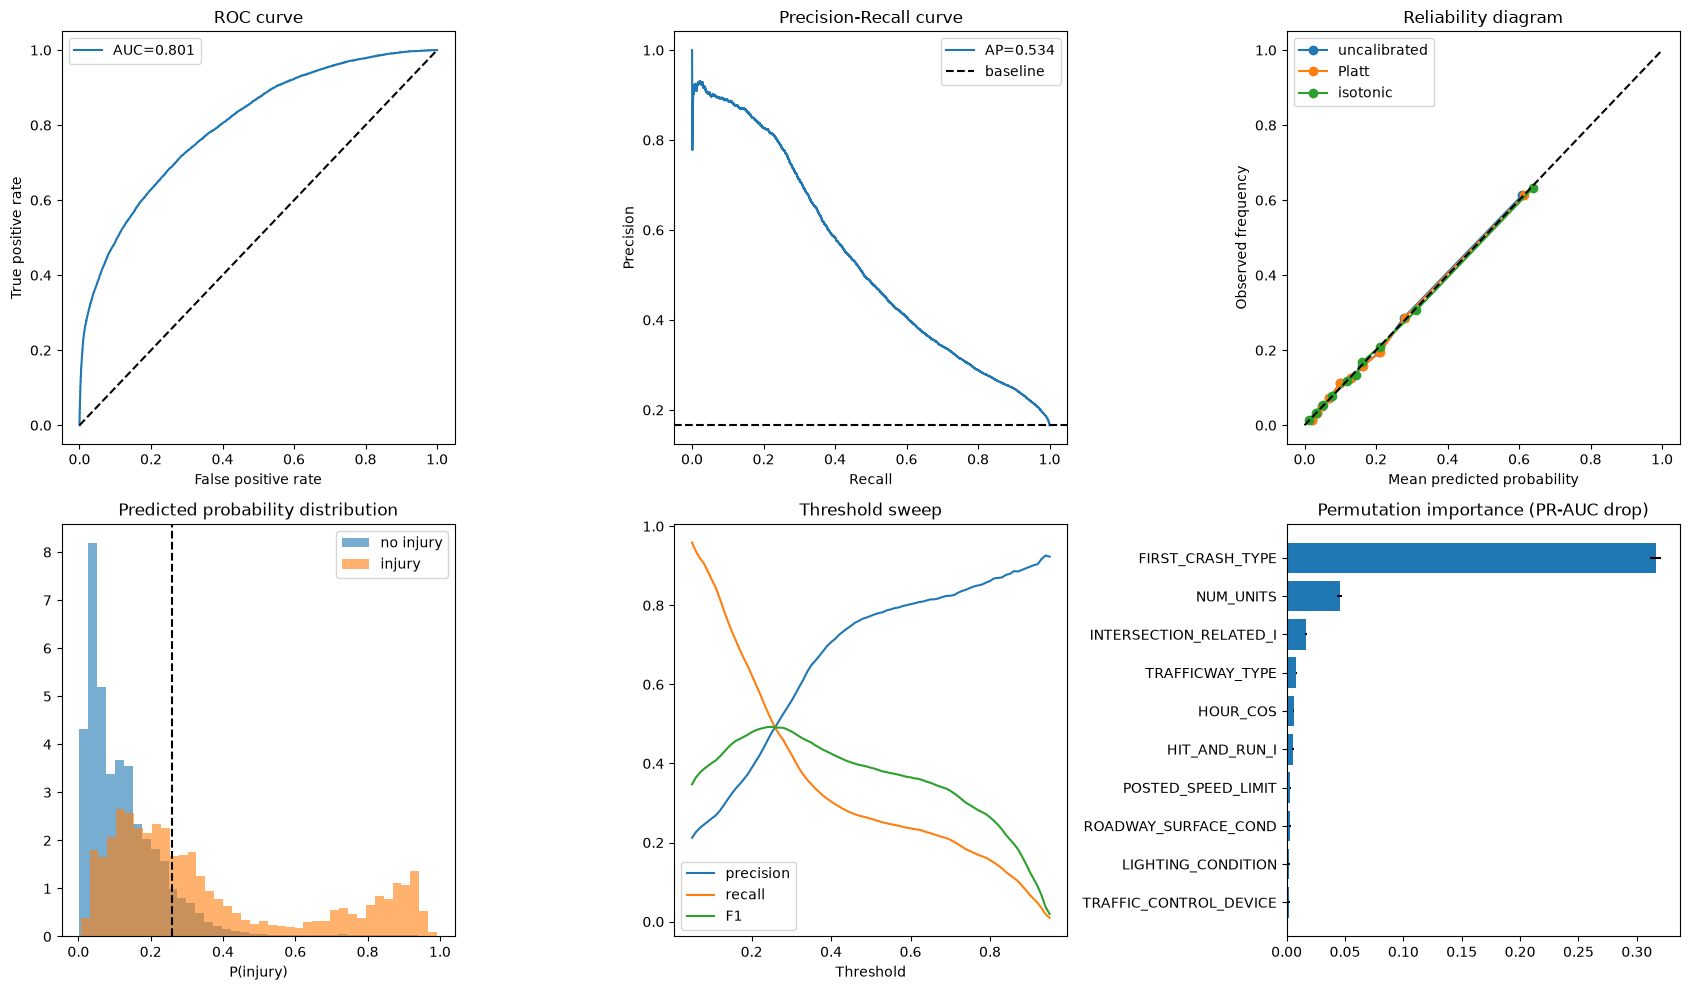


Saved: logreg_evaluation.png, subgroup_results.csv, robustness_results.csv, coefficients.csv, permutation_importance.csv


In [18]:
fig, ax = plt.subplots(2, 3, figsize=(17, 10))

fpr, tpr, _ = roc_curve(y_te, p_te)
ax[0, 0].plot(fpr, tpr, label=f"AUC={roc_auc_score(y_te, p_te):.3f}")
ax[0, 0].plot([0, 1], [0, 1], "k--")
ax[0, 0].set(title="ROC curve", xlabel="False positive rate", ylabel="True positive rate")
ax[0, 0].legend()

prec, rec, _ = precision_recall_curve(y_te, p_te)
ax[0, 1].plot(rec, prec, label=f"AP={average_precision_score(y_te, p_te):.3f}")
ax[0, 1].axhline(y_te.mean(), color="k", ls="--", label="baseline")
ax[0, 1].set(title="Precision-Recall curve", xlabel="Recall", ylabel="Precision")
ax[0, 1].legend()

for lbl, pp in [("uncalibrated", p_te), ("Platt", p_platt), ("isotonic", p_iso)]:
    fr, mp = calibration_curve(y_te, pp, n_bins=10, strategy="quantile")
    ax[0, 2].plot(mp, fr, "o-", label=lbl)
ax[0, 2].plot([0, 1], [0, 1], "k--")
ax[0, 2].set(title="Reliability diagram", xlabel="Mean predicted probability", ylabel="Observed frequency")
ax[0, 2].legend()

ax[1, 0].hist(p_te[y_te == 0], bins=40, alpha=.6, label="no injury", density=True)
ax[1, 0].hist(p_te[y_te == 1], bins=40, alpha=.6, label="injury", density=True)
ax[1, 0].axvline(thr_f1, color="k", ls="--")
ax[1, 0].set(title="Predicted probability distribution", xlabel="P(injury)")
ax[1, 0].legend()

ths = np.linspace(0.05, 0.95, 91)
ax[1, 1].plot(ths, [precision_score(y_te, p_te >= t, zero_division=0) for t in ths], label="precision")
ax[1, 1].plot(ths, [recall_score(y_te, p_te >= t) for t in ths], label="recall")
ax[1, 1].plot(ths, [f1_score(y_te, p_te >= t) for t in ths], label="F1")
ax[1, 1].set(title="Threshold sweep", xlabel="Threshold")
ax[1, 1].legend()

top = pi_df.head(10).iloc[::-1]
ax[1, 2].barh(top["feature"], top["importance"], xerr=top["std"])
ax[1, 2].set(title="Permutation importance (PR-AUC drop)")

plt.tight_layout()
plt.savefig("logreg_evaluation.png", dpi=150)
plt.show()
print("\nSaved: logreg_evaluation.png, subgroup_results.csv, robustness_results.csv, "
      "coefficients.csv, permutation_importance.csv")

## 16. SAVE FILES FOR COMPARISON (ADDED)

Writes the `logreg_*` files used for the head-to-head comparison.

In [19]:
# Same layout as the random forest files so the models can be compared directly.
out = pd.DataFrame({"y_true": y_te, "p_logreg": p_te, "p_logreg_platt": p_platt, "p_logreg_isotonic": p_iso},
                   index=te.index)
if "CRASH_RECORD_ID" in te.columns:
    out.insert(0, "CRASH_RECORD_ID", te["CRASH_RECORD_ID"].values)
out.to_csv("logreg_test_predictions.csv", index_label="row_index")

pd.DataFrame(rows).T.to_csv("logreg_test_metrics_by_threshold.csv")
gen.to_csv("logreg_generalization.csv")
calib.to_csv("logreg_calibration.csv")
pd.DataFrame({k: [np.mean(v), *np.percentile(v, [2.5, 97.5])] for k, v in boot.items()},
             index=["mean", "ci_low", "ci_high"]).T.to_csv("logreg_bootstrap.csv")
pd.Series({
    "train_time_s": train_time,
    "inference_ms_per_1000_rows": 1000 * infer_time / len(X_te) * 1000,
    "model_size_kb": size_kb,
    "cpu_cores": os.cpu_count(),
    "best_C": best_C,
    "threshold_max_f1": thr_f1,
    "threshold_recall90": thr_rec90,
    "test_rows": len(y_te),
    "test_fingerprint": hashlib.md5(np.asarray(te.index).tobytes()).hexdigest()[:8],
}).to_csv("logreg_run_info.csv", header=["value"])
print("Saved logreg_* comparison files")

Saved logreg_* comparison files


## 17. SHIFT TESTS (ADDED)

Not in the original script. Same definitions as the random forest's seasonal and held-out-beat tests.

In [20]:
# Same definitions as the random forest extras, so the shift results are comparable.
RUN_EXTRAS = True
if RUN_EXTRAS:
    print("\n=== Distribution shift (max-F1 threshold from validation) ===")
    shift = {"test (reference)": metrics(y_te, p_te, thr_f1)}

    # (a) Seasonal shift: train on warm months (Apr-Oct), test on warm vs winter
    warm = [4, 5, 6, 7, 8, 9, 10]
    tr_w = tr[tr["CRASH_MONTH"].isin(warm)]
    te_w, te_c = te[te["CRASH_MONTH"].isin(warm)], te[~te["CRASH_MONTH"].isin(warm)]
    if len(te_w) and len(te_c) and te_c["y"].nunique() == 2:
        m_s = build_pipe(best_C, NUM_COLS, CAT_COLS).fit(tr_w[FEATURES], tr_w["y"].values)
        for lbl, d in [("warm->warm (in-distribution)", te_w), ("warm->winter (shifted)", te_c)]:
            shift[lbl] = metrics(d["y"].values, m_s.predict_proba(d[FEATURES])[:, 1], thr_f1)

    # (b) Spatial shift: hold out 25% of police beats from training
    if "BEAT_OF_OCCURRENCE" in df.columns:
        beats = df["BEAT_OF_OCCURRENCE"].dropna().unique()
        held = set(np.random.default_rng(SEED).choice(beats, size=max(1, int(0.25 * len(beats))), replace=False))
        tr_b = tr[~tr["BEAT_OF_OCCURRENCE"].isin(held)]
        te_seen, te_held = te[~te["BEAT_OF_OCCURRENCE"].isin(held)], te[te["BEAT_OF_OCCURRENCE"].isin(held)]
        if len(te_seen) and len(te_held):
            m_b = build_pipe(best_C, NUM_COLS, CAT_COLS).fit(tr_b[FEATURES], tr_b["y"].values)
            for lbl, d in [("seen beats", te_seen), ("held-out beats (shifted)", te_held)]:
                shift[lbl] = metrics(d["y"].values, m_b.predict_proba(d[FEATURES])[:, 1], thr_f1)

    shift_df = pd.DataFrame(shift).T
    print(shift_df[["accuracy", "f1", "recall", "precision", "roc_auc", "pr_auc", "log_loss", "ece"]].round(4).to_string())
    shift_df.to_csv("logreg_shift_results.csv")


=== Distribution shift (max-F1 threshold from validation) ===
                              accuracy      f1  recall  precision  roc_auc  pr_auc  log_loss     ece
test (reference)                0.8314  0.4910  0.4902     0.4919   0.8010  0.5335    0.3509  0.0049
warm->warm (in-distribution)    0.8258  0.5059  0.5166     0.4956   0.8063  0.5473    0.3563  0.0059
warm->winter (shifted)          0.8182  0.4654  0.5100     0.4279   0.7911  0.5054    0.3433  0.0151
seen beats                      0.8312  0.4934  0.4954     0.4914   0.8031  0.5354    0.3498  0.0054
held-out beats (shifted)        0.8279  0.4868  0.4922     0.4816   0.7948  0.5276    0.3541  0.0069
